# RiMEA 02: Walking Speed on Upstairs

A single agent traverses a 10 m stair section. RiMEA verifies that the model reproduces the assigned stair speed and notes that *"the user defines a speed factor"* for stairs. We model the stair as a planar 2 m x 10.4 m corridor (10 m stair plus a 0.4 m start and exit margin) carrying a **`speed_factor = 0.5` zone over the whole corridor**, so the agent walks at **0.5 m/s** and covers the 10 m in about **20.0 s**. The same mechanism serves up and down; only the factor differs.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 19:56 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

## Load and run the scenario

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Rimea-02-upstairs.zip"
scenario = load_scenario(str(SCENARIO_ZIP))
print(scenario.summary())
result = run_scenario(scenario, seed=42)

Scenario: scenario_files/Rimea-02-upstairs.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      60s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         1
  Journeys:      0
  Agents:        ~1
    jps-distributions_0: 1 agents


## Measure the travel time

RiMEA 4.1.1 Test 2 is judged by the time the agent needs for the whole run; expected window [19.5, 20.5] s.

In [6]:
df = result.trajectory_dataframe().sort_values(['id', 'frame'])
LOWER, UPPER = 19.5, 20.5  # accepted travel time, s
travel_time = result.evacuation_time
travel_time

19.71

## Scenario figure

Corridor geometry from the loaded scenario.

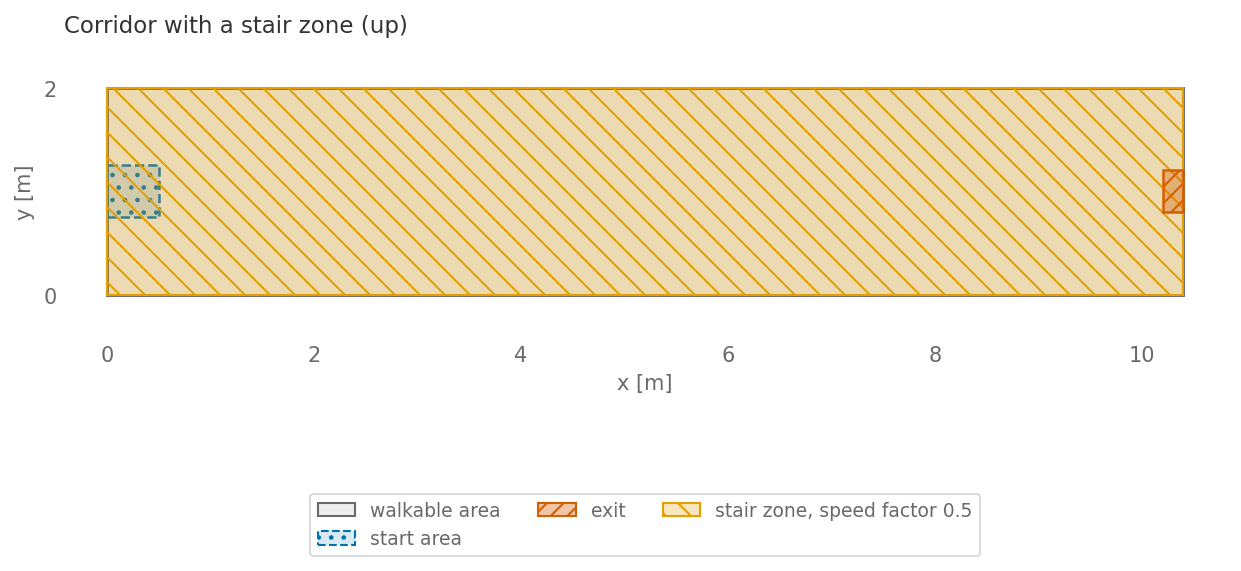

In [7]:
# Scenario geometry from the loaded ZIP.
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(10, 2.6))
    handles = vv_draw_scenario(ax, scenario)
    for z in scenario.zones.values():
        ax.add_patch(MplPolygon(z["coordinates"], closed=True, facecolor=to_rgba(VV_ORANGE, 0.25),
                                edgecolor=VV_ORANGE, hatch="\\\\", linewidth=1.0, zorder=2))
    handles.append(Patch(facecolor=to_rgba(VV_ORANGE, 0.25), edgecolor=VV_ORANGE, hatch="\\\\",
                         label="stair zone, speed factor 0.5"))
    ymin, ymax = scenario.walkable_polygon.bounds[1], scenario.walkable_polygon.bounds[3]
    ax.set_yticks([ymin, ymax])
    ax.set_title("Corridor with a stair zone (up)", loc="left")
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.5), ncol=3)
    plt.show()

## Plot trajectory x vs t

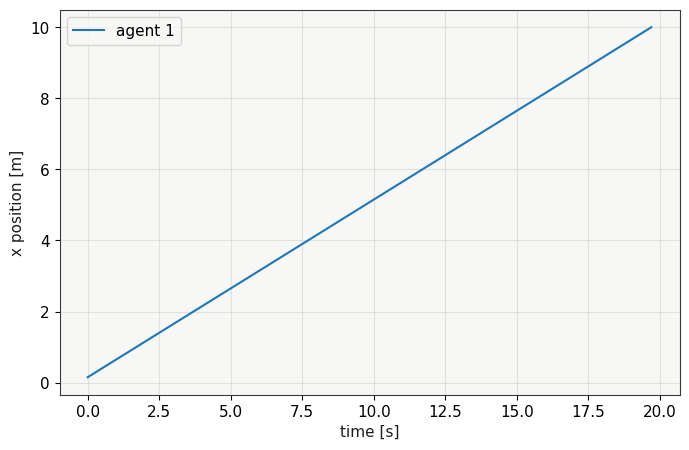

In [8]:
fig, ax = plt.subplots()
for agent_id, sub in df.groupby('id'):
    ax.plot(sub.frame / result.frame_rate, sub.x, label=f'agent {agent_id}')
ax.set_xlabel('time [s]'); ax.set_ylabel('x position [m]'); ax.legend()
plt.show()

## Result figure

Travel time against the accepted window of the acceptance check.

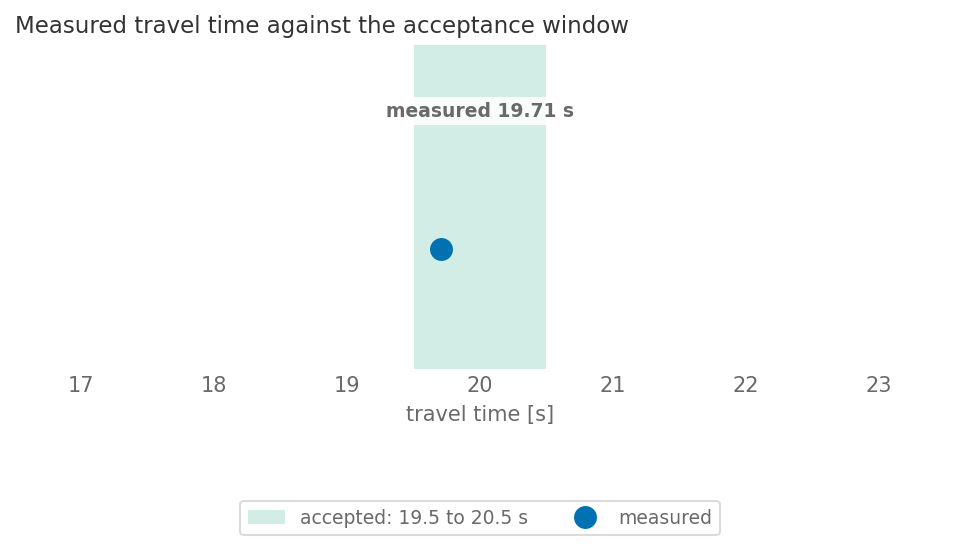

In [9]:
# Travel time against the accepted window.
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(8, 2.8))
    ax.axvspan(LOWER, UPPER, facecolor=to_rgba(VV_GREEN, 0.18), edgecolor=VV_GREEN,
               lw=0, label=f"accepted: {LOWER:g} to {UPPER:g} s")
    ax.plot([travel_time], [0], "o", color=VV_BLUE, ms=10, zorder=4, label="measured")
    lo = min(LOWER - 3, travel_time - 3)
    hi = max(UPPER + 3, travel_time + 3)
    ax.set_xlim(lo, hi)
    ax.set_ylim(-1, 1.7)
    ax.set_yticks([])
    ax.set_xlabel("travel time [s]")
    ax.set_title("Measured travel time against the acceptance window", loc="left")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.38), ncol=2)
    ax.text(0.5, 0.78, f"measured {travel_time:.2f} s",
            transform=ax.transAxes, ha="center", color="dimgrey", fontweight="semibold", fontsize=9,
            bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none", "pad": 2})
    ax.grid(False)
    plt.show()

## Acceptance

The travel time of the whole run must lie in the accepted window; the V&V test (`TestRiMEA02SpeedUpStairs`) uses the same scenario file and the same bounds.

In [10]:
print(f'travel time = {travel_time:.2f} s; accepted window = [{LOWER}, {UPPER}] s')
assert LOWER <= travel_time <= UPPER, travel_time
result.cleanup()

travel time = 19.71 s; accepted window = [19.5, 20.5] s


1